In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

from src.load_uci import load_uci_inertial
from src.results_log import log_run, load_log

tf.keras.utils.set_random_seed(42)   # repeatable results
ACTIVITIES = ["walking", "walking_upstairs", "walking_downstairs"]

X_train, meta_train = load_uci_inertial("train")
X_test, meta_test = load_uci_inertial("test")

# Activity names -> 0, 1, 2 (Keras needs numbers)
to_number = {a: i for i, a in enumerate(ACTIVITIES)}
y_train = meta_train["activity"].map(to_number).to_numpy()
y_test = meta_test["activity"].map(to_number).to_numpy()

# Standardise each of the 9 signals using the TRAINING data only
mean = X_train.mean(axis=(0, 1), keepdims=True)
std = X_train.std(axis=(0, 1), keepdims=True)
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print(f"Train: {X_train.shape}   Test: {X_test.shape}")

2026-10-20 10:55:38.943396: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Train: (3285, 128, 9)   Test: (1387, 128, 9)


In [2]:
model = models.Sequential()
model.add(layers.Input(shape=(128, 9)))
model.add(layers.Conv1D(32, 3, activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Conv1D(32, 3, activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling1D(2))
model.add(layers.Dropout(0.2))
model.add(layers.Conv1D(64, 3, activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Conv1D(64, 3, activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling1D(2))
model.add(layers.Dropout(0.3))
model.add(layers.Conv1D(128, 3, activation='relu', padding='same'))
model.add(layers.BatchNormalization())
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(3))

model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [3]:
history = model.fit(X_train, y_train, epochs=15, batch_size=64,
                    validation_data=(X_test, y_test), verbose=2)

predictions = np.array(ACTIVITIES)[model.predict(X_test, verbose=0).argmax(axis=1)]
y_test_names = np.array(ACTIVITIES)[y_test]

print(f"\nAccuracy: {accuracy_score(y_test_names, predictions):.3f}")
print(f"Macro F1: {f1_score(y_test_names, predictions, average='macro'):.3f}\n")
print(classification_report(y_test_names, predictions, digits=3))

run_folder = log_run("CNN", "UCI train", "UCI test",
                     np.array(ACTIVITIES)[y_train], y_test_names, predictions, notes="baseline CNN")

Epoch 1/15
52/52 - 6s - 113ms/step - accuracy: 0.7869 - loss: 0.6079 - val_accuracy: 0.3410 - val_loss: 2.3248
Epoch 2/15
52/52 - 2s - 43ms/step - accuracy: 0.9756 - loss: 0.0686 - val_accuracy: 0.3482 - val_loss: 4.4974
Epoch 3/15
52/52 - 2s - 39ms/step - accuracy: 0.9903 - loss: 0.0282 - val_accuracy: 0.3699 - val_loss: 4.6388
Epoch 4/15
52/52 - 2s - 38ms/step - accuracy: 0.9951 - loss: 0.0137 - val_accuracy: 0.6200 - val_loss: 1.8722
Epoch 5/15
52/52 - 2s - 38ms/step - accuracy: 0.9954 - loss: 0.0169 - val_accuracy: 0.8219 - val_loss: 0.6728
Epoch 6/15
52/52 - 2s - 37ms/step - accuracy: 0.9954 - loss: 0.0122 - val_accuracy: 0.9113 - val_loss: 0.3798
Epoch 7/15
52/52 - 2s - 39ms/step - accuracy: 0.9991 - loss: 0.0018 - val_accuracy: 0.9524 - val_loss: 0.1766
Epoch 8/15
52/52 - 2s - 39ms/step - accuracy: 0.9948 - loss: 0.0139 - val_accuracy: 0.9452 - val_loss: 0.2115
Epoch 9/15
52/52 - 2s - 38ms/step - accuracy: 0.9976 - loss: 0.0076 - val_accuracy: 0.9661 - val_loss: 0.1536
Epoch 10/

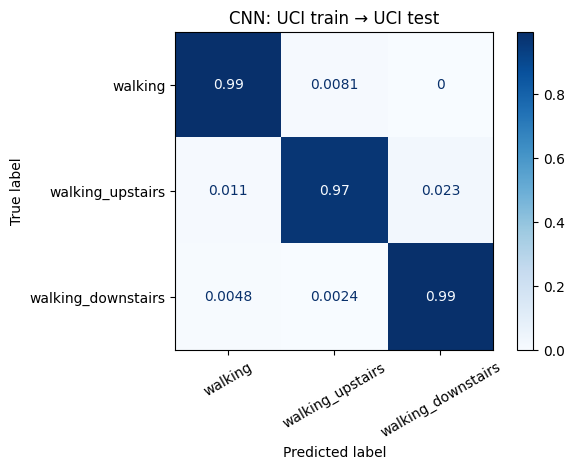

In [4]:
ConfusionMatrixDisplay.from_predictions(y_test_names, predictions, labels=ACTIVITIES, normalize="true",
                                        cmap="Blues", xticks_rotation=30)
plt.title("CNN: UCI train → UCI test")
plt.tight_layout()
plt.savefig(run_folder / "confusion_matrix.png", dpi=150)
plt.show()

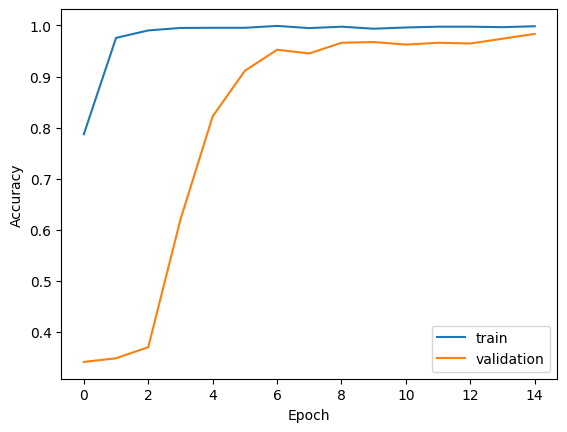

In [5]:
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.savefig(run_folder / "training_curve.png", dpi=150)
plt.show()

In [6]:
load_log()

,run_id,model,train_data,test_data,train_windows,test_windows,train_walking,train_walking_upstairs,train_walking_downstairs,accuracy,macro_f1,f1_walking,f1_walking_upstairs,f1_walking_downstairs,notes
0,2026-10-13_16-30-52,Logistic Regression,UCI train,UCI test,3285,1387,1226,1073,986,0.8709,0.8701,0.8830,0.8539,0.8734,first LR run on UCI dataset
1,2026-10-13_16-31-27,Random Forest,UCI train,UCI test,3285,1387,1226,1073,986,0.8854,0.8853,0.8891,0.8808,0.8861,first RF run on UCI dataset
2,2026-10-20_10-56-26,CNN,UCI train,UCI test,3285,1387,1226,1073,986,0.9834,0.9833,0.9889,0.9774,0.9835,baseline CNN
